<h1>CRISP DM template (fi)</h1>

<h2>1. Business understanding</h2>

   - `Määritellään ratkaistava liiketoimintaongelma (business problem).`
   - `Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).`

The goal of this project is to classify color images from the CIFAR-10 dataset into ten different classes using a `Fully Connected Network` (FCN). The models performance will be evaluated using test accuracy and learning curves. The results will also be compared with a `Convolutional Neural Network` (CNN) to investigate how different network architectures affect image classification.

Realistic accuracy for <b>FCN</b> is 50-55% and ambitious accuracy is 57-60%<br>
Realistic accuracy for <b>CNN</b> is 75-80& and ambitious accuracy is 82-85%

<h2>2. Data understanding</h2>

   - `Kerätään ja tutkitaan saatavilla olevaa dataa.`
   - `Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).`


The CIFAR-10 dataset contains `60,000 color images` divided into ten classes. Each image has a resolution of `32×32 pixels` and three color channels (red, green, blue). The dataset is divided into 50,000 training images and 10,000 test images.

Here we explore the dataset.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow" #choosing the back end, "tensorflow", "torch" or "jax"

import keras
from keras import layers
from keras.layers import Input, Flatten, Dense
from keras.datasets import cifar10
from keras.models import Sequential
from keras.utils import to_categorical

import numpy as np
import matplotlib.pyplot as plt

print(keras.__version__, keras.backend.backend()) #keras library version

3.15.1 tensorflow


In [2]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data() #keras downloads dataset, which has been already divided to test and train data.

In [3]:
print("X_train:", X_train.shape) 
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (50000, 32, 32, 3)
y_train: (50000, 1)
X_test: (10000, 32, 32, 3)
y_test: (10000, 1)


Above we inspected the datas dimensions. 50,000 training images, each 32×32 pixels with 3 color channels and one integer label (0-9) per image. Same for 10,000 test images.

Next we find a picture example from the data by typing a sample number. Then we are provided witht the picture and the class number as a title.

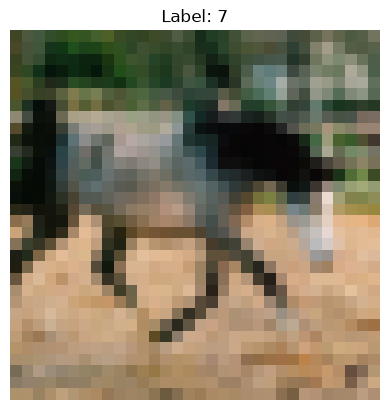

In [4]:
sample_number = 52 #find different images
plt.imshow(X_train[sample_number])
plt.title(f'Label: {y_train[sample_number][0]}')
plt.axis('off')
plt.show()

<h2>3. Data preparation</h2>

   - `Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).`
   - `Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.`

CIFAR-10 data was clean from the start, so changes or clean ups were unnecessary. Pixel values were divided by 255, in which case they are in the range 0–1. It ensures better learning. And do to that,  type was changed into float because of the division.

The labes were changed into one-hot-form with `to_categorical.`

In [5]:
# Data preparation
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

<h2>4. Modeling</h2>

 - `Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).`
 - `Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.`
 - `Millä perusteella tehty valinnat`
 - `Taulukko on hyvä viestimiseen`
 - `Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.`

<b>Fully Connected Network</b>

We continue by flattening each image into 3,072 values, pass them trough 2 hidden layers to learn patterns and outputs probabilities for the 10 classes with softmax. The model is then compiled with "adam" optimizer as trought testing, we found it to be more accurate compared to the alternative "rmsprop" optimizer.

The model is trained for 20 epochs in batches of 32 images (because the size of the data), using 10% of the training data for validation and the training history is saved for plotting learning curves.

In [6]:
model = Sequential([
    Input(shape=(32, 32, 3)), #image shape, 3 for the colors
    Flatten(), #image to one dimencional vector 32×32×3 = 3,072
    Dense(512, activation='relu'), #learns patterns from the pixel values using 512 neurons
    Dense(256, activation='relu'), #256 neurons, each looking at all 512 outputs of the previous layer
    Dense(10, activation='softmax') #produces probabilities for the 10 possible classes
    ])

In [7]:
#compiling. tells how the model should be taught
model.compile(optimizer='adam', #rmsprop (alternative)
              loss='categorical_crossentropy', #measures how wrong the model is
              metrics=['accuracy'])

In [13]:
history = model.fit( #the model can be trained with the training data
    X_train,
    y_train,
    epochs=18, #how many times model goes trough data
    batch_size=32, #the model updates its weights in batches of 32 images.
    validation_split=0.1 #10% of the training data is used for validation
) 

Epoch 1/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.4930 - loss: 1.4161 - val_accuracy: 0.4428 - val_loss: 1.5418
Epoch 2/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.4970 - loss: 1.3982 - val_accuracy: 0.4652 - val_loss: 1.5423
Epoch 3/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.5058 - loss: 1.3806 - val_accuracy: 0.4812 - val_loss: 1.4710
Epoch 4/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.5141 - loss: 1.3618 - val_accuracy: 0.4662 - val_loss: 1.4986
Epoch 5/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.5184 - loss: 1.3492 - val_accuracy: 0.4830 - val_loss: 1.4837
Epoch 6/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.5239 - loss: 1.3330 - val_accuracy: 0.4946 - val_loss: 1.4398
Epoch 7/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.5289 - loss: 1.3192 - val_accuracy: 0.4968 - val_loss: 1.4325
Epoch 8/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 24s 17ms/step - accuracy: 0.5308 -

<h2>5. Evaluation</h2>

 - `Arvioidaan mallin todellinen onnistuminen.`
 - `Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).`<br>
 - `Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.`

Now we can evaluate the trained neural network on data it has not trained on, using the test data (X_test, y_test). The goal was to get the accuracy over 50%, but insted it stays just a little below so far.

In [14]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4981 - loss: 1.4724
Test accuracy: 0.49810001254081726


Below it's displayed how the neural network is structured, how data flows through its layers, and how many parameters it has.

In [10]:
model.summary()   # parametrien määrä

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121,824 (19.54 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,414,550 (13.03 MB)

Using code plotting we can see how well the neural network learns and whether it might be overfitting. Ideally, both losses decrease as training progresses. 

Both curves seem to descent steadily. Until epoch 3 is reached. There the validation begins it's ascending, before it decreases again at epoch 5.

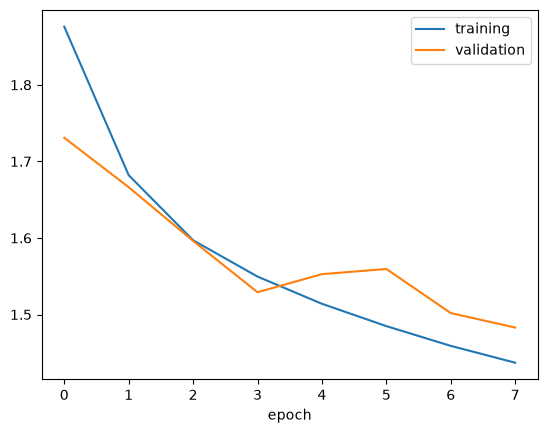

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="training")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

Here we checks how well the neural network classifies images from the test dataset and displays its prediction alongside the correct answer. It lets you compare what the image actually represents with what the neural network predicts.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


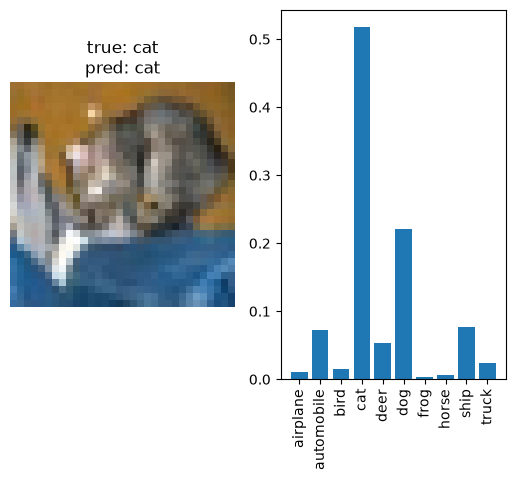

In [12]:
class_names = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

probs = model.predict(X_test)
i = 0   #change pic from here
plt.subplot(1, 2, 1)
plt.imshow(X_test[i]); plt.axis("off")
plt.title(f"true: {class_names[y_test[i].argmax()]}\npred: {class_names[probs[i].argmax()]}")
plt.subplot(1, 2, 2)
plt.bar(class_names, probs[i]); plt.xticks(rotation=90)
plt.show()

<h2>6. Deployment</h2>

- `Malli viedään käytäntöön (deployment).`
- `Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.`